ref_

1. https://timhanewich.medium.com/how-i-trained-a-neural-network-to-play-tetris-using-reinforcement-learning-ecfa529c767a
2. 

In [1]:
!pip install gym[all]
!pip install gym-tetris
!pip install pyvirtualdisplay
!sudo apt-get update
!sudo apt-get install -y xvfb ffmpeg freeglut3-dev
!pip install 'imageio==2.4.0'
!pip install pyvirtualdisplay
!pip install tf-agents[reverb]
!pip install pyglet
!pip install swig
!pip install gym[atari,box2d,accept-rom-license]  #install gym and virtual display

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 374.4/374.4 kB 16.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 297.0/297.0 kB 15.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 56.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 45.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 66.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.4/243.4 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 98.7/98.7 kB 6.4 MB/s eta 0:00:00
  error: subprocess-exited-with-error
  
  × python setup.py bdist_wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error origin

In [2]:
from __future__ import absolute_import, division, print_function

import base64
import imageio
import IPython
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import PIL.Image
import pyvirtualdisplay
import reverb

import tensorflow as tf

from tf_agents.agents.dqn import dqn_agent
from tf_agents.drivers import py_driver
from tf_agents.environments import suite_gym
from tf_agents.environments import tf_py_environment
from tf_agents.eval import metric_utils
from tf_agents.metrics import tf_metrics
from tf_agents.networks import sequential
from tf_agents.policies import py_tf_eager_policy
from tf_agents.policies import random_tf_policy
from tf_agents.replay_buffers import reverb_replay_buffer
from tf_agents.replay_buffers import reverb_utils
from tf_agents.trajectories import trajectory
from tf_agents.specs import tensor_spec
from tf_agents.utils import common

from tf_agents.environments import  suite_gym
from tf_agents.environments.atari_preprocessing import AtariPreprocessing
from tf_agents.environments.atari_wrappers import FrameStack4
import gym

# To get smooth animations
import matplotlib.animation as animation
matplotlib.rc('animation', html='jshtml')

In [3]:
import gym
import gym_tetris
import numpy as np
import matplotlib.pyplot as plt


In [4]:
#entorno con wrappers cargados./ ALE tetris co
env = suite_gym.load(environment_name="ALE/Tetris-v5",max_episode_steps=27000, gym_env_wrappers=[AtariPreprocessing,FrameStack4])

print(env)
print(env.gym)

<FrameStack4<AtariPreprocessing<TimeLimit<OrderEnforcing<AtariEnv<ALE/Tetris-v5>>>>>>


In [5]:
env.seed(42)
env.reset()


TimeStep(
{'step_type': array(0, dtype=int32),
 'reward': array(0., dtype=float32),
 'discount': array(1., dtype=float32),
 'observation': array([[[ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        ...,
        [20, 20, 20, 20],
        [20, 20, 20, 20],
        [20, 20, 20, 20]],

       [[78, 78, 78, 78],
        [78, 78, 78, 78],
        [78, 78, 78, 78],
        ...,
        [98, 98, 98, 98],
        [98, 98, 98, 98],
        [98, 98, 98, 98]],

       [[98, 98, 98, 98],
        [98, 98, 98, 98],
        [98, 98, 98, 98],
        ...,
        [98, 98, 98, 98],
        [98, 98, 98, 98],
        [98, 98, 98, 98]],

       ...,

       [[ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        ...,
        [ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        [ 0,  0,  0,  0]],

       [[ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        ...,
        [ 0,  0,  0,  0],
        [ 0,  0,  0,  0],
        [ 0,  0,  0, 

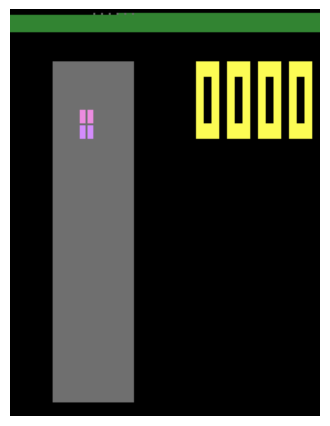

In [6]:
env.reset()
img = env.render(mode="rgb_array")
plt.figure(figsize=(4, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

In [7]:
# display
display = pyvirtualdisplay.Display(visible=0, size=(1400, 900)).start()

In [8]:
from tf_agents.environments.tf_py_environment import TFPyEnvironment
tf_env = TFPyEnvironment(env)

In [9]:
#ESPECIFICACIONES 
print('Acciones disponibles:\n{}\r\n'.format(env.gym.get_action_meanings()))
print('Observaciones:\n{}'.format(env.observation_spec()))

Acciones disponibles:
['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'DOWN']

Observaciones:
BoundedArraySpec(shape=(84, 84, 4), dtype=dtype('uint8'), name='observation', minimum=0, maximum=255)


(84, 84, 4)


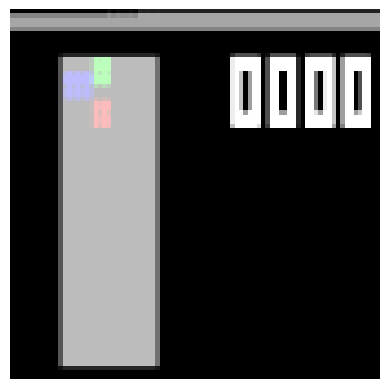

In [10]:
#Algunos ejemplos de acciones en el juego
env.reset()
time_step = env.step(np.array(1)) # FIRE
time_step = env.step(np.array(3)) # RIGHT
time_step = env.step(np.array(4)) # DOWNRIGHT

observation = time_step.observation.astype(np.float32)

#Como existen 3 canales de colores, no podemos mostrar 4 frames.
image = observation[..., :3]
image = np.clip(image / 150, 0, 1)
plt.imshow(image)
plt.axis("off")
print(observation.shape)

In [11]:
from tf_agents.networks.q_network import QNetwork
#convertir observacinoes a float float 32, normalizando.. (valores  0.0 a 1.0) 
preprocessing_layer = tf.keras.layers.Lambda( lambda obs: tf.cast(obs, np.float32) / 255.)

#arquitectura:
#conv_layer_params=[(32, (8, 8), 4), (64, (4, 4), 2), (64, (3, 3), 1)]
conv_layer_params=[(32, (8, 8), 4) , (64, (4, 4), 2)]#, (64, (3, 3), 1), (1024, (7, 7), 1)]
#layer dense com 512 por uma cama de sair de 4 unidades
fc_layer_params=(1024,)

q_network = QNetwork(tf_env.observation_spec(), tf_env.action_spec()
                     ,preprocessing_layers=preprocessing_layer
                     ,conv_layer_params=conv_layer_params
                     ,fc_layer_params=fc_layer_params)
q_network.summary

<bound method Network.summary of <tf_agents.networks.q_network.QNetwork object at 0x7cfa01353ac0>>

In [12]:
from tf_agents.agents.dqn.dqn_agent import DqnAgent

train_step = tf.Variable(0)
update_period = 4 
#optimizer = keras.optimizers.Adam(lr=2.5e-4, rho=0.95, momentum=0.1,epsilon=0.00001, centered=True)
optimizer = tf.compat.v1.train.RMSPropOptimizer(learning_rate=2.5e-4, decay=0.95, momentum=0.0,
                                     epsilon=0.00001, centered=True)
#optimizer = keras.optimizers.Adam(lr=0.00005,epsilon=0.00001)
epsilon_fn = tf.keras.optimizers.schedules.PolynomialDecay(
    initial_learning_rate=0.8,
    decay_steps=250000 // update_period, 
    end_learning_rate=0.01)

agent = DqnAgent(tf_env.time_step_spec(),
                 tf_env.action_spec(),
                 q_network=q_network,
                 optimizer=optimizer,
                 target_update_period=2000, 
                 #La función de pérdida debe devolver un error por instancia, por lo que definimos reducción="none" 
                 td_errors_loss_fn=tf.keras.losses.Huber(reduction="none"),
                 gamma=0.89, # discount factor
                 train_step_counter=train_step,
                 epsilon_greedy=lambda: epsilon_fn(train_step))
agent.initialize()

In [13]:
from tf_agents.replay_buffers import tf_uniform_replay_buffer

#data_spec datos que se guardarán en el búfer.
#batch_size es el número de trayectorias que se deben agregar a cada paso.
#max_length es la longitud máxima de reproducción. (Documento DQN2015: Cuidado con el acaparador de RAM)

replay_buffer = tf_uniform_replay_buffer.TFUniformReplayBuffer( data_spec=agent.collect_data_spec,    batch_size=tf_env.batch_size, max_length=300000)#ojo para el entrenamiento

replay_buffer_observer = replay_buffer.add_batch

In [14]:
from tf_agents.metrics import tf_metrics
from tf_agents.eval.metric_utils import log_metrics
import logging

train_metrics = [
    tf_metrics.NumberOfEpisodes(),
    tf_metrics.EnvironmentSteps(),
    tf_metrics.AverageReturnMetric(),
    tf_metrics.AverageEpisodeLengthMetric(),
]
logging.getLogger().setLevel(logging.INFO)
log_metrics(train_metrics)

In [15]:
from tf_agents.drivers.dynamic_step_driver import DynamicStepDriver

collect_driver = DynamicStepDriver(
    tf_env,
    agent.collect_policy,
    observers=[replay_buffer_observer] + train_metrics,
    num_steps=update_period) 
collect_driver

In [16]:
from tf_agents.policies.random_tf_policy import RandomTFPolicy

class ShowProgress:
    def __init__(self, total):
        self.counter = 0
        self.total = total
    def __call__(self, trajectory):
        if not trajectory.is_boundary():
            self.counter += 1
        if self.counter % 100 == 0:
            print("\r{}/{}".format(self.counter, self.total), end="")

initial_collect_policy = RandomTFPolicy(tf_env.time_step_spec(),
                                        tf_env.action_spec())
init_driver = DynamicStepDriver(
    tf_env,
    initial_collect_policy,
    observers=[replay_buffer.add_batch, ShowProgress(20000)],
    num_steps=20000)
final_time_step, final_policy_state = init_driver.run()

20000/20000

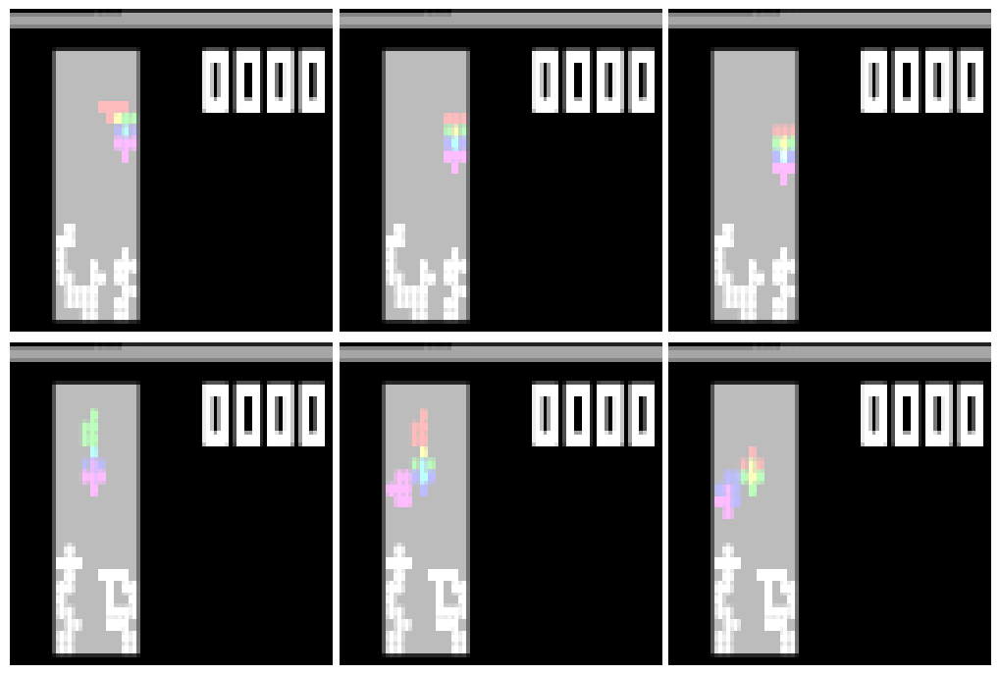

In [17]:
dataset = replay_buffer.as_dataset(
    sample_batch_size=64,
    num_steps=17,
    num_parallel_calls=3
).prefetch(3)
iterator = iter(dataset)
trajectories, buffer_info = next(iterator)
plt.figure(figsize=(10, 6.8))
for row in range(2):
    for col in range(3):
        plt.subplot(2, 3, row * 3 + col + 1)
        obs = trajectories.observation[row, col].numpy().astype(np.float32)
        img = obs[..., :3]
        current_frame_delta = np.maximum(obs[..., 3] - obs[..., :3].mean(axis=-1), 0.)
        img[..., 0] += current_frame_delta
        img[..., 2] += current_frame_delta
        img = np.clip(img / 150, 0, 1)
        plt.imshow(img)
        plt.axis("off")
plt.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0, wspace=0.02)
plt.show()

In [18]:
dataset = replay_buffer.as_dataset(
    sample_batch_size=64,
    num_steps=2,
    num_parallel_calls=3).prefetch(3)

In [19]:
#convertir funciones
from tf_agents.utils.common import function

collect_driver.run = function(collect_driver.run)
agent.train = function(agent.train)

In [20]:
def train_agent(n_iterations):
    time_step = None
    policy_state = agent.collect_policy.get_initial_state(tf_env.batch_size)
    iterator = iter(dataset)
    for iteration in range(n_iterations):
        time_step, policy_state = collect_driver.run(time_step, policy_state)
        trajectories, buffer_info = next(iterator)
        train_loss = agent.train(trajectories)
        print("\r{} loss: {:.5f}".format(
            iteration, train_loss.loss.numpy()), end="")
        if iteration % 1000 == 0:
            log_metrics(train_metrics)

In [21]:
#el valor ideal para n_iterations es 1.000.000
num_iterations_ = 100000 #ojo entrenamiento
train_agent(n_iterations=num_iterations_)

99999 loss: 0.00000

In [22]:
def update_scene(num, frames, patch):
    patch.set_data(frames[num])
    return patch

def plot_animation(frames, repeat=False, interval=40):
    fig = plt.figure()
    patch = plt.imshow(frames[0])
    plt.axis('on')
    anim = animation.FuncAnimation(
        fig, update_scene, fargs=(frames, patch),
        frames=len(frames), repeat=repeat, interval=interval)
    plt.close()
    return anim

In [23]:
frames = []
def save_frames(trajectory):
    global frames
    frames.append(tf_env.pyenv.envs[0].render(mode="rgb_array"))

prev_lives = tf_env.pyenv.envs[0].ale.lives()
def reset_and_fire_on_life_lost(trajectory):
    global prev_lives
    lives = tf_env.pyenv.envs[0].ale.lives()
    if prev_lives != lives:
        tf_env.reset()
        tf_env.pyenv.envs[0].step(np.array(tf_env.pyenv.envs[0].action_space.sample()))
        prev_lives = lives

watch_driver = DynamicStepDriver(
    tf_env,
    agent.policy,
    observers=[save_frames, reset_and_fire_on_life_lost, ShowProgress(1000)],
    num_steps=1000)
final_time_step, final_policy_state = watch_driver.run()

plot_animation(frames)

1000/1000